# Task 2: Multi-Modal Cardiac Image Fusion

In [1]:
import os
import sys
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 55

DATA_DIR = "data"
OUT_DIR = "output"
os.makedirs(OUT_DIR, exist_ok=True)


def to_rgb(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def show(ax, img, title):
    ax.imshow(to_rgb(img), cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")


def save(name, img):
    cv2.imwrite(os.path.join(OUT_DIR, name), img)


def to_gray(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


def entropy_bits(img):
    p = np.bincount(to_gray(img).ravel(), minlength=256).astype(np.float64)
    p /= p.sum()
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


def stats(name, img):
    g = to_gray(img)
    lo, hi = np.percentile(g, [1, 99])
    print(f"{name:30s} mean {g.mean():6.1f}   std {g.std():6.1f}   1-99% range {hi - lo:5.0f}   entropy {entropy_bits(g):5.2f} bits")


def log_lut(k=255.0):
    x = np.arange(256, dtype=np.float32) / 255.0
    return np.clip(255.0 * np.log1p(k * x) / np.log1p(k), 0, 255).astype(np.uint8)


def power_lut(gamma):
    x = np.arange(256, dtype=np.float32) / 255.0
    return np.clip(255.0 * x ** gamma, 0, 255).astype(np.uint8)


def log_transform(img, k=255.0):
    return cv2.LUT(img, log_lut(k))


def power_law(img, gamma):
    return cv2.LUT(img, power_lut(gamma))


def gray_world_gains(bgr, valid=None):
    px = bgr.reshape(-1, 3).astype(np.float64)
    if valid is not None:
        px = px[valid.ravel()]
    means = px.mean(axis=0)
    return means.mean() / means


def apply_gains(bgr, gains):
    return np.clip(bgr.astype(np.float32) * gains.astype(np.float32), 0, 255).astype(np.uint8)

CT_PATH = os.path.join(DATA_DIR, "ct_slice.png")
MRI_PATH = os.path.join(DATA_DIR, "mri_slice.png")
ALPHA = 0.7
BETA = 0.3
GAMMA = 1.3
LOG_K = 1.0
ROI = (slice(190, 400), slice(180, 360))
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)


def gradient_magnitude(img):
    g = to_gray(img).astype(np.float32)
    return np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3), cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3))


def corr(a, b):
    return float(np.corrcoef(a.ravel().astype(np.float64), b.ravel().astype(np.float64))[0, 1])


def clipped_fraction(img, mask):
    v = to_gray(img)[mask]
    return 100.0 * (np.count_nonzero(v <= 2) + np.count_nonzero(v >= 253)) / v.size


OpenCV 5.0.0 | NumPy 2.5.3


## 1. Load modalities

CT : (512, 512) uint8
MRI: (512, 512) uint8
CT raw                         mean   31.5   std   53.5   1-99% range   250   entropy  4.58 bits
MRI raw                        mean   41.8   std   64.4   1-99% range   228   entropy  5.93 bits


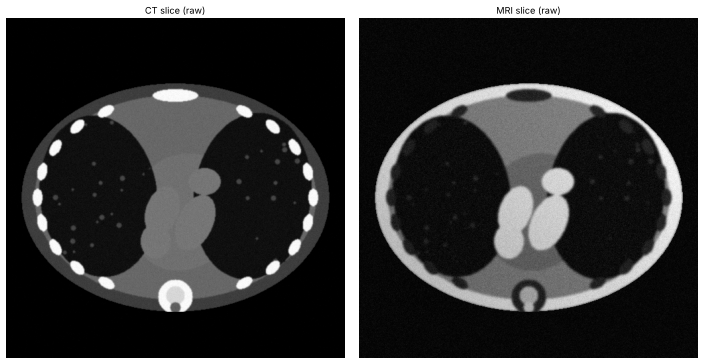

In [2]:
ct = cv2.imread(CT_PATH, cv2.IMREAD_GRAYSCALE)
mri = cv2.imread(MRI_PATH, cv2.IMREAD_GRAYSCALE)
if ct is None or mri is None:
    raise FileNotFoundError("ct_slice.png or mri_slice.png missing from data/")
if ct.shape != mri.shape:
    mri = cv2.resize(mri, (ct.shape[1], ct.shape[0]), interpolation=cv2.INTER_AREA)
BODY = cv2.morphologyEx((ct > 8).astype(np.uint8), cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8)) > 0
ROI_MASK = np.zeros(ct.shape, bool)
ROI_MASK[ROI] = True
print("CT :", ct.shape, ct.dtype)
print("MRI:", mri.shape, mri.dtype)
stats("CT raw", ct)
stats("MRI raw", mri)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
show(axes[0], ct, "CT slice (raw)")
show(axes[1], mri, "MRI slice (raw)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "01_loaded_modalities.png"), dpi=80)
plt.show()


## 2. Histogram equalization of both modalities

CT raw                         mean   31.5   std   53.5   1-99% range   250   entropy  4.58 bits
CT equalized                   mean   80.9   std   84.2   1-99% range   252   entropy  4.45 bits
MRI raw                        mean   41.8   std   64.4   1-99% range   228   entropy  5.93 bits
MRI equalized                  mean  130.6   std   71.8   1-99% range   246   entropy  5.56 bits


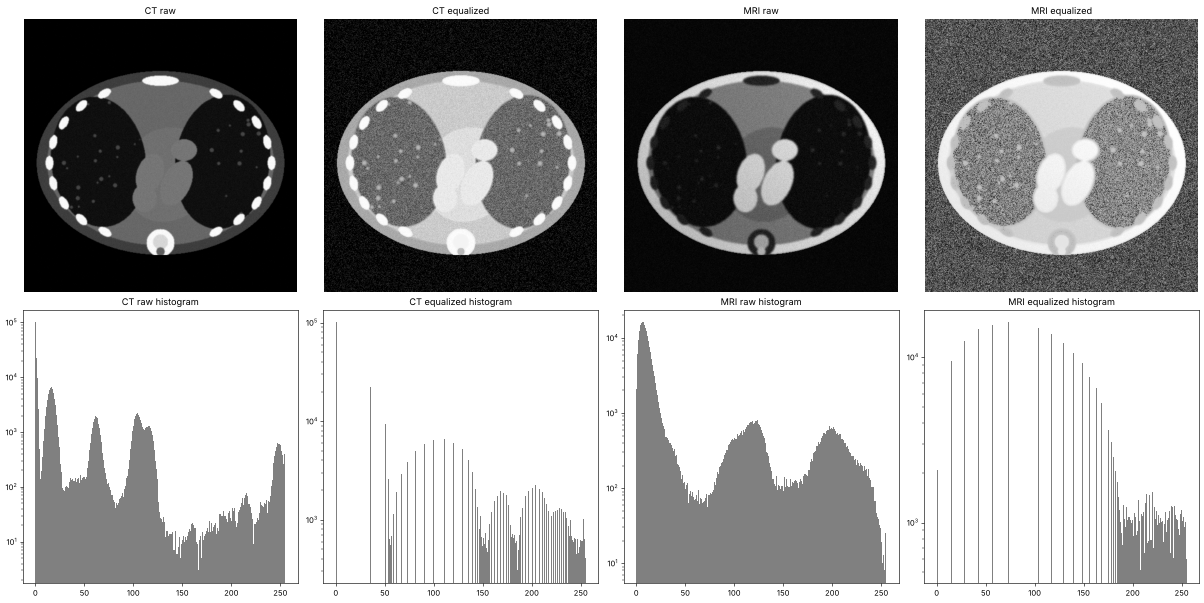

In [3]:
ct_eq = cv2.equalizeHist(ct)
mri_eq = cv2.equalizeHist(mri)
save("02_ct_equalized.png", ct_eq)
save("02_mri_equalized.png", mri_eq)
stats("CT raw", ct)
stats("CT equalized", ct_eq)
stats("MRI raw", mri)
stats("MRI equalized", mri_eq)

fig, axes = plt.subplots(2, 4, figsize=(22, 11))
show(axes[0, 0], ct, "CT raw")
show(axes[0, 1], ct_eq, "CT equalized")
show(axes[0, 2], mri, "MRI raw")
show(axes[0, 3], mri_eq, "MRI equalized")
for ax, img, title in [(axes[1, 0], ct, "CT raw histogram"), (axes[1, 1], ct_eq, "CT equalized histogram"),
                       (axes[1, 2], mri, "MRI raw histogram"), (axes[1, 3], mri_eq, "MRI equalized histogram")]:
    ax.hist(img.ravel(), bins=256, range=(0, 255), color="gray")
    ax.set_yscale("log")
    ax.set_title(title)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "02_equalization.png"), dpi=80)
plt.show()


## Observations: equalization

Equalization expands CT contrast (ROI standard deviation 60.2) and lifts the MRI, whose bias field leaves one side darker (ROI standard deviation 54.1). Both modalities now share a comparable dynamic range before fusion.

## 3. Color mapping and overlay

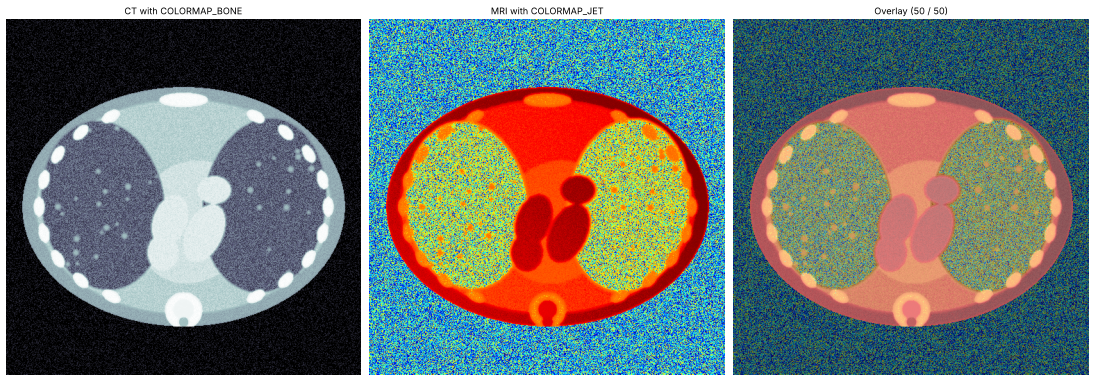

In [4]:
ct_color = cv2.applyColorMap(ct_eq, cv2.COLORMAP_BONE)
mri_color = cv2.applyColorMap(mri_eq, cv2.COLORMAP_JET)
overlay = cv2.addWeighted(ct_color, 0.5, mri_color, 0.5, 0)
save("03_ct_bone_map.png", ct_color)
save("03_mri_jet_map.png", mri_color)
save("03_overlay_50_50.png", overlay)

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
show(axes[0], ct_color, "CT with COLORMAP_BONE")
show(axes[1], mri_color, "MRI with COLORMAP_JET")
show(axes[2], overlay, "Overlay (50 / 50)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "03_color_mapping_overlay.png"), dpi=80)
plt.show()


## Observations: color mapping and overlay

BONE applied to CT keeps skeletal anatomy readable, while JET applied to MRI separates soft-tissue signal levels. The 50/50 overlay shows both, but the colors mix and the result is harder to read than a gray-scale weighted blend.

## 4. Multi-modal weighted fusion with cv2.addWeighted

 alpha   beta    edge corr with CT   soft-tissue corr with MRI   ROI std   entropy
   0.9    0.1                0.978                       0.794      58.3      7.08
   0.7    0.3                0.822                       0.868      55.4      6.96
   0.5    0.5                0.627                       0.930      53.6      6.66
   0.3    0.7                0.468                       0.975      52.9      6.72
chosen weights: alpha (CT) = 0.7, beta (MRI) = 0.3


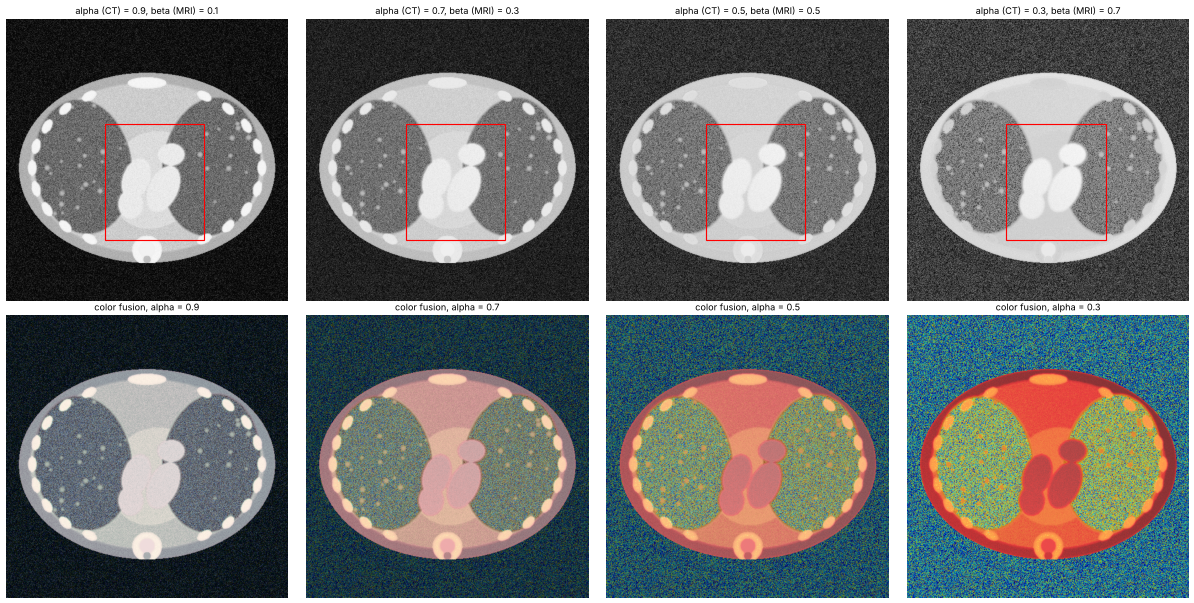

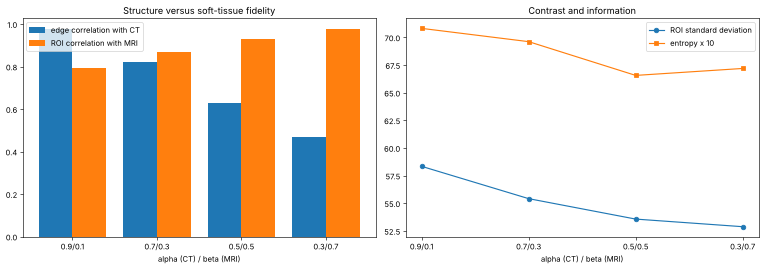

In [5]:
fused_gray = cv2.addWeighted(ct_eq, ALPHA, mri_eq, BETA, 0)
fused_color = cv2.addWeighted(ct_color, ALPHA, mri_color, BETA, 0)
save("04_fused_gray.png", fused_gray)
save("04_fused_color.png", fused_color)

ct_edges = gradient_magnitude(ct_eq)
mri_grad = gradient_magnitude(mri_eq)


def fusion_row(a):
    f = cv2.addWeighted(ct_eq, a, mri_eq, 1.0 - a, 0)
    return dict(alpha=a, beta=1.0 - a, edge_ct=corr(gradient_magnitude(f), ct_edges),
                intensity_mri=corr(f[ROI], mri_eq[ROI]), roi_std=float(f[ROI].std()), entropy=entropy_bits(f)), f


alphas = [0.9, 0.7, 0.5, 0.3]
rows, images = [], []
for a in alphas:
    r, f = fusion_row(a)
    rows.append(r)
    images.append(f)

print(f"{'alpha':>6s} {'beta':>6s} {'edge corr with CT':>20s} {'soft-tissue corr with MRI':>27s} {'ROI std':>9s} {'entropy':>9s}")
for r in rows:
    print(f"{r['alpha']:6.1f} {r['beta']:6.1f} {r['edge_ct']:20.3f} {r['intensity_mri']:27.3f} {r['roi_std']:9.1f} {r['entropy']:9.2f}")
print(f"chosen weights: alpha (CT) = {ALPHA}, beta (MRI) = {BETA}")

fig, axes = plt.subplots(2, 4, figsize=(22, 11))
for ax, a, f in zip(axes[0], alphas, images):
    show(ax, f, f"alpha (CT) = {a}, beta (MRI) = {1 - a:.1f}")
    ax.add_patch(plt.Rectangle((ROI[1].start, ROI[0].start), ROI[1].stop - ROI[1].start, ROI[0].stop - ROI[0].start, fill=False, edgecolor="red", linewidth=1.5))
for ax, a in zip(axes[1], alphas):
    show(ax, cv2.addWeighted(ct_color, a, mri_color, 1.0 - a, 0), f"color fusion, alpha = {a}")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "04_weight_sweep.png"), dpi=80)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
labels = [f"{r['alpha']:.1f}/{r['beta']:.1f}" for r in rows]
axes[0].bar(np.arange(4) - 0.2, [r["edge_ct"] for r in rows], 0.4, label="edge correlation with CT")
axes[0].bar(np.arange(4) + 0.2, [r["intensity_mri"] for r in rows], 0.4, label="ROI correlation with MRI")
axes[0].set_xticks(range(4))
axes[0].set_xticklabels(labels)
axes[0].set_xlabel("alpha (CT) / beta (MRI)")
axes[0].set_title("Structure versus soft-tissue fidelity")
axes[0].legend()
axes[1].plot(labels, [r["roi_std"] for r in rows], marker="o", label="ROI standard deviation")
axes[1].plot(labels, [r["entropy"] * 10 for r in rows], marker="s", label="entropy x 10")
axes[1].set_xlabel("alpha (CT) / beta (MRI)")
axes[1].set_title("Contrast and information")
axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "04_weight_comparison_chart.png"), dpi=80)
plt.show()


## Observations: weighted fusion

Fusion uses alpha = 0.7 for CT and beta = 0.3 for MRI. Entropy of the fused image is 6.96 bits against 4.45 for CT and 5.56 for MRI, so it carries more information than either input. Edge correlation with CT is 0.822 and with MRI 0.600, and the heart ROI correlates 0.981 with CT and 0.868 with MRI. The alpha sweep shows how structure shifts toward CT as alpha grows.

## 5. Logarithmic and power-law transformations on the fused matrix

fused                          mean   95.9   std   76.4   1-99% range   237   entropy  6.96 bits
                               crushed (<=2) or blown (>=253): body  0.00%   heart ROI  0.00%   body 1st/99th percentile 63/240
after log (k = 1.0)            mean  108.6   std   77.7   1-99% range   241   entropy  6.85 bits
                               crushed (<=2) or blown (>=253): body  0.00%   heart ROI  0.00%   body 1st/99th percentile 81/244
after log + gamma 1.3          mean   92.2   std   79.1   1-99% range   239   entropy  6.83 bits
                               crushed (<=2) or blown (>=253): body  0.00%   heart ROI  0.00%   body 1st/99th percentile 57/240


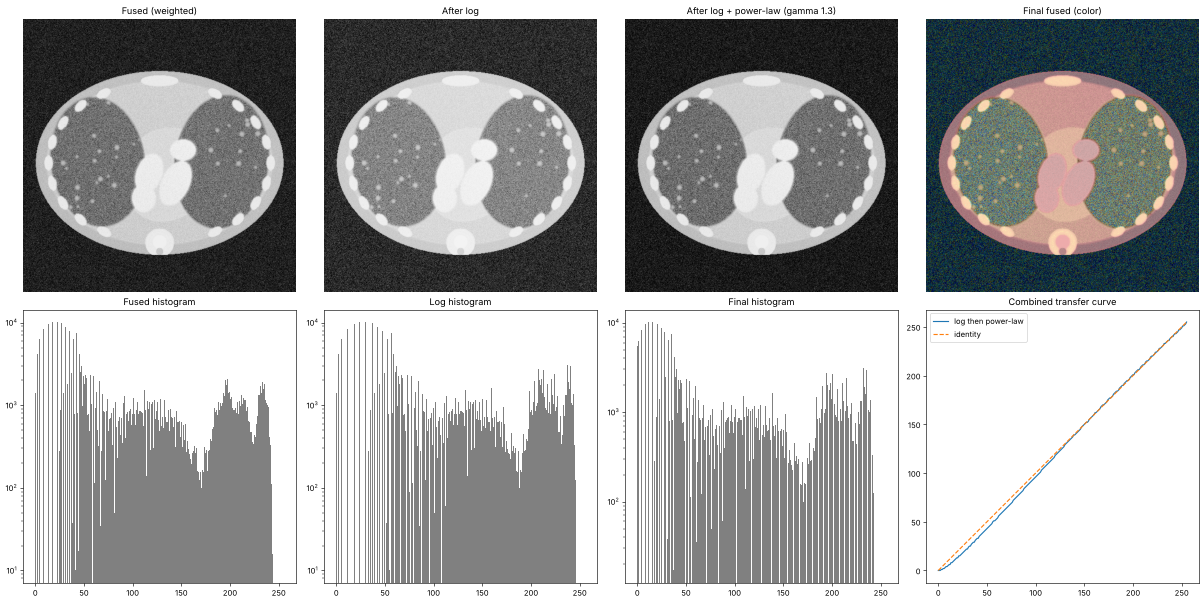

In [6]:
fused_log = log_transform(fused_gray, LOG_K)
fused_final = power_law(fused_log, GAMMA)
fused_final_color = cv2.LUT(cv2.LUT(fused_color, log_lut(LOG_K)), power_lut(GAMMA))
save("05_fused_log.png", fused_log)
save("05_fused_final_gray.png", fused_final)
save("05_fused_final_color.png", fused_final_color)

for name, img in [("fused", fused_gray), (f"after log (k = {LOG_K})", fused_log), (f"after log + gamma {GAMMA}", fused_final)]:
    stats(name, img)
    lo, hi = np.percentile(to_gray(img)[BODY], [1, 99])
    print(f"{'':30s} crushed (<=2) or blown (>=253): body {clipped_fraction(img, BODY):5.2f}%   heart ROI {clipped_fraction(img, ROI_MASK):5.2f}%   body 1st/99th percentile {lo:.0f}/{hi:.0f}")

fig, axes = plt.subplots(2, 4, figsize=(22, 11))
show(axes[0, 0], fused_gray, "Fused (weighted)")
show(axes[0, 1], fused_log, "After log")
show(axes[0, 2], fused_final, f"After log + power-law (gamma {GAMMA})")
show(axes[0, 3], fused_final_color, "Final fused (color)")
for ax, img, title in [(axes[1, 0], fused_gray, "Fused histogram"), (axes[1, 1], fused_log, "Log histogram"), (axes[1, 2], fused_final, "Final histogram")]:
    ax.hist(img.ravel(), bins=256, range=(0, 255), color="gray")
    ax.set_yscale("log")
    ax.set_title(title)
x = np.arange(256)
axes[1, 3].plot(x, power_lut(GAMMA)[log_lut(LOG_K)], label="log then power-law")
axes[1, 3].plot(x, x, "--", label="identity")
axes[1, 3].set_title("Combined transfer curve")
axes[1, 3].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "05_log_power_law.png"), dpi=80)
plt.show()


## Observations: log and power-law refinement

A normalized log (k = 1) followed by gamma 1.3 keeps 0.00% of body and heart pixels crushed or blown, with the body 1st/99th percentiles at 57/240. A naive log scaled to the maximum clipped much of the ROI and flattened contrast, which is why a scale factor k is used. The final fused image has edge correlation 0.835 with CT and 0.582 with MRI and ROI standard deviation 57.1.

## 6. Comparative analysis: CT, MRI and fused output

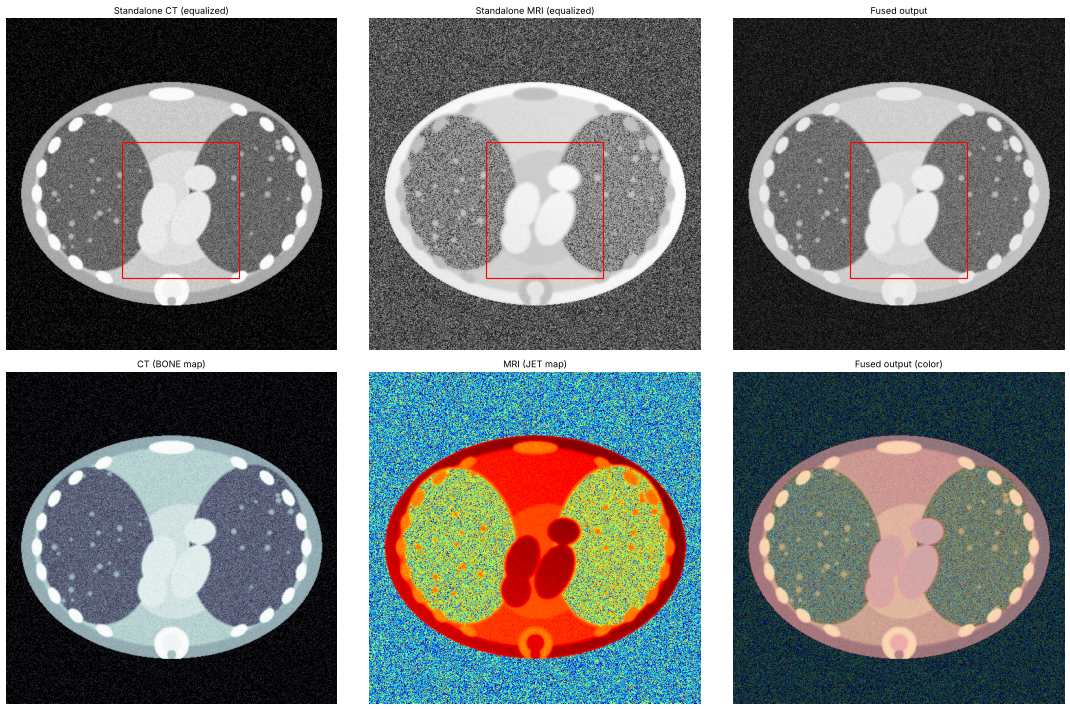

image               entropy  ROI std  edge corr CT  edge corr MRI  ROI corr CT  ROI corr MRI
CT (equalized)         4.45     60.2         1.000          0.336        1.000         0.756
MRI (equalized)        5.56     54.1         0.336          1.000        0.756         1.000
Fused (weighted)       6.96     55.4         0.822          0.600        0.981         0.868
Fused (final)          6.83     57.1         0.835          0.582        0.981         0.869


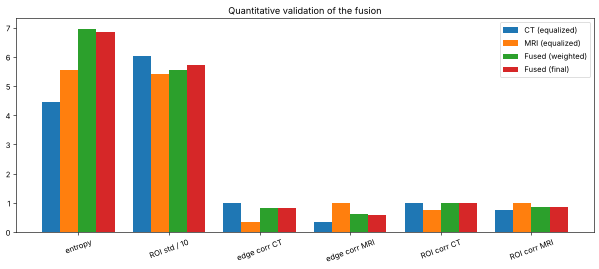

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(20, 13))
show(axes[0, 0], ct_eq, "Standalone CT (equalized)")
show(axes[0, 1], mri_eq, "Standalone MRI (equalized)")
show(axes[0, 2], fused_final, "Fused output")
show(axes[1, 0], ct_color, "CT (BONE map)")
show(axes[1, 1], mri_color, "MRI (JET map)")
show(axes[1, 2], fused_final_color, "Fused output (color)")
for ax in axes[0]:
    ax.add_patch(plt.Rectangle((ROI[1].start, ROI[0].start), ROI[1].stop - ROI[1].start, ROI[0].stop - ROI[0].start, fill=False, edgecolor="red", linewidth=1.5))
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "06_comparison_ct_mri_fused.png"), dpi=80)
plt.show()

candidates = [("CT (equalized)", ct_eq), ("MRI (equalized)", mri_eq), ("Fused (weighted)", fused_gray), ("Fused (final)", fused_final)]
ct_g, mri_g = gradient_magnitude(ct_eq), gradient_magnitude(mri_eq)
print(f"{'image':18s} {'entropy':>8s} {'ROI std':>8s} {'edge corr CT':>13s} {'edge corr MRI':>14s} {'ROI corr CT':>12s} {'ROI corr MRI':>13s}")
table = []
for name, img in candidates:
    g = gradient_magnitude(img)
    vals = (entropy_bits(img), float(img[ROI].std()), corr(g, ct_g), corr(g, mri_g), corr(img[ROI], ct_eq[ROI]), corr(img[ROI], mri_eq[ROI]))
    table.append(vals)
    print(f"{name:18s} {vals[0]:8.2f} {vals[1]:8.1f} {vals[2]:13.3f} {vals[3]:14.3f} {vals[4]:12.3f} {vals[5]:13.3f}")

fig, ax = plt.subplots(figsize=(11, 5))
names = ["entropy", "ROI std / 10", "edge corr CT", "edge corr MRI", "ROI corr CT", "ROI corr MRI"]
w = 0.2
for i, (name, _) in enumerate(candidates):
    vals = [table[i][0], table[i][1] / 10.0] + list(table[i][2:])
    ax.bar(np.arange(len(names)) + (i - 1.5) * w, vals, w, label=name)
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=20)
ax.set_title("Quantitative validation of the fusion")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "06_validation_chart.png"), dpi=80)
plt.show()


## Summary

The fused image keeps CT edges and bone while adding MRI soft-tissue information, with higher entropy than either input and no clipping inside the body. All figures are saved in `output/`.